In [1]:
import os
import pickle
import sys
import threading
import time

import numpy as np
import matplotlib.pyplot as plt

root_dir = os.path.abspath("..")
data_dir = os.path.join(root_dir, "data")
figs_dir = os.path.join(root_dir, "figs")
os.makedirs(data_dir, exist_ok=True)
if root_dir not in sys.path:
    sys.path.append(root_dir)

from current_setpoints.models.machines import ieee_machine2_trained_neural_flux_and_torque
from current_setpoints.models.forward_model import ForwardModel, Fault, count_peaks_at_limit
from current_setpoints.optimization import (
    StaticOptimizer,
    ActiveSetOptimizer,
    FeasibilityOptimizer,
    calculate_grid,
    grid_to_data,
)
from current_setpoints.utils.plotting import plot_grid_segments


def call_with_timeout(timeout, fn, *args, **kwargs):
    """Same mechanism as grid.py's own _call_with_timeout (plain daemon thread, not
    ThreadPoolExecutor -- see that function's docstring for why: an executor's worker
    threads are tracked by concurrent.futures.thread's own atexit handler, which blocks
    interpreter/kernel shutdown until every such thread finishes, even abandoned ones).
    Duplicated locally rather than importing grid.py's private helper, matching how every
    other sweep notebook this session keeps its own copy."""
    result = {}

    def _run():
        try:
            result["value"] = fn(*args, **kwargs)
        except Exception as exc:
            result["error"] = exc

    t = threading.Thread(target=_run, daemon=True)
    t.start()
    t.join(timeout)
    if t.is_alive():
        return None, "timeout"
    if "error" in result:
        return None, f"exception: {result['error']!r}"
    return result.get("value"), None

In [2]:
CURR_MAX = 30.0
VOLT_MAX = 13.0
OMEGA_MAX = 1800.0

SLSQP_OPTS = {"disp": False, "ftol": 1e-8, "maxiter": 500}
QUICK = os.environ.get("MAP_QUICK") == "1"
MAP_VARIANT = os.environ.get("MAP_VARIANT", "fix")
TORQUE_BAND = {"fix": 0.0, "band": 0.02}[MAP_VARIANT]
N_GRID = 30 if QUICK else 60

N_TORQ = 3 if QUICK else 23
N_OMEGA = 3 if QUICK else 23
COARSE_TOP = 0.8
TORQ_TOP = 1.02
PROBE_TIMEOUT_SECONDS = 2400
CELL_TIMEOUT_SECONDS = 900

drive = ieee_machine2_trained_neural_flux_and_torque(curr_max=CURR_MAX, volt_max=VOLT_MAX)
fwd = ForwardModel(drive, n_theta=700, fault=Fault(()))
const_mech_speed = 30.0 / (np.pi * drive.n_ppairs)
dim = drive.dim

optimizer_static = StaticOptimizer(fwd, opts=SLSQP_OPTS)
optimizer_dynamic_old = ActiveSetOptimizer(fwd, opts=SLSQP_OPTS, n_grid=N_GRID,
                                           torque_ripple=TORQUE_BAND, torque_ripple_relative=True)
optimizer_dynamic_new = FeasibilityOptimizer(fwd, opts=SLSQP_OPTS, n_grid=N_GRID)

MODEL_TAG = "tauR"
VARIANT_TAG = {"fix": "fix", "band": "fix_band2"}[MAP_VARIANT]
run_tag = f"{N_TORQ}x{N_OMEGA}_N{N_GRID}_{MODEL_TAG}_{VARIANT_TAG}" + ("_quick" if QUICK else "")
png_dir_static = os.path.join(figs_dir, f"map_static_neural_flux_torque_{run_tag}")
png_dir_dynamic_old = os.path.join(figs_dir, f"map_dynamic_neural_flux_torque_{run_tag}")
os.makedirs(png_dir_static, exist_ok=True)
os.makedirs(png_dir_dynamic_old, exist_ok=True)
summary_dir = os.path.join(figs_dir, f"map_summary_neural_flux_torque_{run_tag}")
os.makedirs(summary_dir, exist_ok=True)

print(f"healthy mode, model {MODEL_TAG}, variant {MAP_VARIANT} (torque band {100 * TORQUE_BAND:g} %), N_GRID={N_GRID}, "
      f"grid {N_TORQ}x{N_OMEGA}, run tag {run_tag}")

healthy mode, model tauR, N_GRID=60, grid 23x23, run tag 23x23_N60_tauR


In [3]:
def _representative_dq(curr_dq):
    return curr_dq if curr_dq.ndim == 1 else np.nanmean(curr_dq, axis=0)


vec_omega = np.linspace(0.0, OMEGA_MAX / const_mech_speed, N_OMEGA)

tmax_static_row = np.full(N_OMEGA, np.nan)
tmax_old_row = np.full(N_OMEGA, np.nan)
curr_at_tmax_static = np.full((dim, N_OMEGA), np.nan)
curr_at_tmax_old = np.full((dim, N_OMEGA), np.nan)

probe_pkl = os.path.join(data_dir, f"torque_speed_map_probe_neural_flux_torque_{run_tag}.pkl")
probe_cached = os.path.isfile(probe_pkl)
if probe_cached:
    with open(probe_pkl, "rb") as f:
        _p = pickle.load(f)
    tmax_static_row, tmax_old_row = _p["tmax_static_row"], _p["tmax_old_row"]
    curr_at_tmax_static, curr_at_tmax_old = _p["curr_at_tmax_static"], _p["curr_at_tmax_old"]
    print(f"loaded cached max-torque probe from {probe_pkl}")
t0 = time.perf_counter()
prev_margin = 1.0
for idx_omega, omega in enumerate([] if probe_cached else vec_omega):
    omega = float(omega)
    sol_s, err_s = call_with_timeout(PROBE_TIMEOUT_SECONDS, optimizer_static.maximize_torque, omega)
    if sol_s is not None and sol_s.success:
        tmax_static_row[idx_omega] = sol_s.torque
        curr_at_tmax_static[:, idx_omega] = _representative_dq(sol_s.curr_dq)

    sol_o, err_o = call_with_timeout(
        PROBE_TIMEOUT_SECONDS, optimizer_dynamic_old.maximize_torque, omega, None, prev_margin
    )
    if sol_o is not None and sol_o.success:
        tmax_old_row[idx_omega] = sol_o.torque
        curr_at_tmax_old[:, idx_omega] = _representative_dq(sol_o.curr_dq)
        prev_margin = sol_o.diagnostics.get("margin", prev_margin)

    print(f"  probe {idx_omega + 1}/{N_OMEGA}: {omega * const_mech_speed:.1f} RPM  "
          f"static={tmax_static_row[idx_omega]:.3f}  dynamic={tmax_old_row[idx_omega]:.3f}  "
          f"(margin={prev_margin:.2f})")

if not probe_cached:
    print(f"probing done in {time.perf_counter() - t0:.0f}s")
    with open(probe_pkl, "wb") as f:
        pickle.dump({"tmax_static_row": tmax_static_row, "tmax_old_row": tmax_old_row,
                     "curr_at_tmax_static": curr_at_tmax_static, "curr_at_tmax_old": curr_at_tmax_old}, f)

seed0 = drive.seeds()[0]
nan_cols_static = ~np.isfinite(tmax_static_row)
nan_cols_old = ~np.isfinite(tmax_old_row)
curr_at_tmax_static[:, nan_cols_static] = seed0[:, None]
curr_at_tmax_old[:, nan_cols_old] = seed0[:, None]

shared_ref = np.nanmax(np.stack([tmax_static_row, tmax_old_row]), axis=0)
shared_ref = np.nan_to_num(shared_ref, nan=0.0)

n_coarse = max(2, round(N_TORQ * 9 / 25))
n_fine = N_TORQ - n_coarse
frac = np.concatenate([
    np.linspace(0.0, COARSE_TOP, n_coarse),
    COARSE_TOP + (TORQ_TOP - COARSE_TOP) * np.arange(1, n_fine + 1) / n_fine,
])
grid_torq_neural = np.outer(frac, shared_ref)

guess_static = np.broadcast_to(curr_at_tmax_static[:, None, :], (dim, N_TORQ, N_OMEGA)).copy()
guess_old = np.broadcast_to(curr_at_tmax_old[:, None, :], (dim, N_TORQ, N_OMEGA)).copy()

vec_torq_placeholder = frac * float(np.nanmax(shared_ref))

dict_grid_corr_static = {
    "vec_torq": vec_torq_placeholder, "vec_omega": vec_omega,
    "grid_torq_neural": grid_torq_neural, "curr_dq_grid": guess_static,
}
dict_grid_corr_old = {
    "vec_torq": vec_torq_placeholder, "vec_omega": vec_omega,
    "grid_torq_neural": grid_torq_neural, "curr_dq_grid": guess_old,
}

  probe 1/23: 0.0 RPM  static=7.786  dynamic=8.016  (margin=1.00)
  probe 2/23: 81.8 RPM  static=7.782  dynamic=8.009  (margin=1.00)
  probe 3/23: 163.6 RPM  static=7.778  dynamic=8.003  (margin=1.00)
  probe 4/23: 245.5 RPM  static=7.773  dynamic=7.996  (margin=1.00)
  probe 5/23: 327.3 RPM  static=7.766  dynamic=7.989  (margin=1.00)
  probe 6/23: 409.1 RPM  static=7.759  dynamic=7.982  (margin=1.00)
  probe 7/23: 490.9 RPM  static=7.751  dynamic=7.975  (margin=1.00)
  probe 8/23: 572.7 RPM  static=7.740  dynamic=7.970  (margin=1.00)
  probe 9/23: 654.5 RPM  static=7.728  dynamic=7.950  (margin=1.00)
  probe 10/23: 736.4 RPM  static=7.715  dynamic=7.915  (margin=0.99)
  probe 11/23: 818.2 RPM  static=7.700  dynamic=7.880  (margin=0.99)
  probe 12/23: 900.0 RPM  static=7.685  dynamic=7.867  (margin=0.99)
  probe 13/23: 981.8 RPM  static=7.670  dynamic=7.833  (margin=0.99)
  probe 14/23: 1063.6 RPM  static=7.659  dynamic=7.823  (margin=0.99)
  probe 15/23: 1145.5 RPM  static=7.650  dyna

In [4]:
PHASE_LETTERS = ["a", "b", "c", "d", "e"]


def segment_label(n_curr, n_volt):
    roman = {0: "", 1: "I", 2: "II"}
    return f"MTPA_{n_curr}" if n_volt == 0 else f"FW_{roman[n_volt]},{n_curr}"


def fine_idx_grid(fwd, theta_grid):
    n_theta = fwd.vec_theta.size - 1
    return np.round(theta_grid / (2 * np.pi) * n_theta).astype(int) % n_theta


def alpha_beta_xy(theta_grid, sched):
    c1, s1 = np.cos(theta_grid), np.sin(theta_grid)
    c3, s3 = np.cos(3 * theta_grid), np.sin(3 * theta_grid)
    id1, iq1, id3, iq3 = sched[:, 0], sched[:, 1], sched[:, 2], sched[:, 3]
    i_alpha = c1 * id1 - s1 * iq1
    i_beta = s1 * id1 + c1 * iq1
    i_x = c3 * id3 - s3 * iq3
    i_y = s3 * id3 + c3 * iq3
    return i_alpha, i_beta, i_x, i_y


def waveforms_for_plot(fwd, omega, curr_dq, n_theta_plot=360):
    """(theta_deg, sched, iph, vph, theta_v_deg) for either a constant (static, curr_dq.ndim==1)
    or per-node-trajectory (dynamic, curr_dq.ndim==2) current, on a common convention suitable
    for the 9-panel diagnostic plot. Static is swept fresh over n_theta_plot samples of the
    SAME constant vector (current doesn't change over the cycle, only its phase reconstruction
    does, since the dq->phase map itself rotates with theta); dynamic reuses each node's own
    angle/current directly.

    Dynamic voltage: PDF eq. (7) with the current running linearly between nodes, i.e. WITH the
    dynamic term (omega/dtheta) L (i_next - i_n) -- two values per node, just before theta_n (end
    of the incoming segment) and just after it (start of the outgoing one), the same voltages
    ActiveSetOptimizer limits and grid.py's _trajectory_waveforms reports. vph then has 2 columns
    per node, plotted against theta_v_deg (each node angle twice)."""
    kept = list(fwd.fault._kept)
    dynamic = curr_dq.ndim == 2
    if not dynamic:
        theta_grid = np.linspace(0.0, 2 * np.pi, n_theta_plot, endpoint=False)
        sched = np.tile(curr_dq, (n_theta_plot, 1))
        idx_grid = fine_idx_grid(fwd, theta_grid)
        n_pts = n_theta_plot
    else:
        n_pts = curr_dq.shape[0]
        theta_grid = np.linspace(0.0, 2 * np.pi, n_pts, endpoint=False)
        idx_grid = fine_idx_grid(fwd, theta_grid)
        sched = curr_dq
    coupling = omega / (2 * np.pi / n_pts)

    iph = np.full((len(kept), n_pts), np.nan)
    vph = np.full((len(kept), 2 * n_pts if dynamic else n_pts), np.nan)
    for k, ti in enumerate(idx_grid):
        i_n = sched[k]
        if not np.all(np.isfinite(i_n)):
            continue
        iph[:, k] = fwd.phase_map_at_theta(int(ti)) @ i_n
        gU, gL, bV = fwd.volt_map_at_theta(int(ti), omega, i_n)
        v_steady = gU @ i_n + bV
        if dynamic:
            i_prev, i_next = sched[(k - 1) % n_pts], sched[(k + 1) % n_pts]
            vph[:, 2 * k] = (v_steady + coupling * (gL @ (i_n - i_prev)))[kept]
            vph[:, 2 * k + 1] = (v_steady + coupling * (gL @ (i_next - i_n)))[kept]
        else:
            vph[:, k] = v_steady[kept]
    theta_deg = np.rad2deg(theta_grid)
    theta_v_deg = np.repeat(theta_deg, 2) if dynamic else theta_deg
    return theta_deg, sched, iph, vph, theta_v_deg


def classify_status(sol):
    if sol is None:
        return "TIMEOUT_OR_ERROR"
    if sol.success:
        return "FEASIBLE"
    if isinstance(sol.diagnostics, dict) and sol.diagnostics.get("fail_reason") == "R0 failed at some nodes":
        return "R0_INFEASIBLE"
    return "STUCK"


def save_grid_point_plot(fwd, omega, torque, rpm, sol, save_path):
    """9-panel diagnostic plot, same layout as pointwise_waveform_diagnostics.ipynb /
    feasibility_sweep_infeasible_healthy.ipynb (DQ setpoints, phase currents, phase voltages,
    Joule-loss density, DQ norm, alphabeta current, xy current, achieved torque, spectrum).
    Handles BOTH a constant (static, sol.curr_dq.ndim==1) and per-node-trajectory (dynamic)
    current via waveforms_for_plot. Called unconditionally (even on failure/timeout) so
    infeasible points get plotted too -- matching feasibility_sweep_infeasible_healthy.ipynb's
    convention -- as long as there's at least one finite current to show."""
    status = classify_status(sol)
    curr_max, volt_max = fwd.drive.curr_max, fwd.drive.volt_max

    curr_dq = sol.curr_dq if sol is not None else None
    if curr_dq is None or not np.any(np.isfinite(curr_dq)):
        return status

    theta, sched, iph, vph, theta_v = waveforms_for_plot(fwd, omega, curr_dq)

    n_curr = count_peaks_at_limit(np.concatenate([iph, iph[:, :1]], axis=1), curr_max) if np.any(np.isfinite(iph)) else 0
    n_volt = count_peaks_at_limit(np.concatenate([vph, vph[:, :1]], axis=1), volt_max) if np.any(np.isfinite(vph)) else 0
    seg_text = segment_label(n_curr, n_volt) if curr_dq.ndim == 1 else ""

    kept = list(fwd.fault._kept)
    letters = [PHASE_LETTERS[p] for p in kept]

    i_alpha, i_beta, i_x, i_y = alpha_beta_xy(np.deg2rad(theta), sched)
    norm_pw = np.sum(sched ** 2, axis=1)
    cu_pw = np.nansum(iph ** 2, axis=0)
    torque_pw = np.array([
        fwd.drive.torque(omega, sched[k]) if np.all(np.isfinite(sched[k])) else np.nan
        for k in range(sched.shape[0])
    ])

    have_fft = np.all(np.isfinite(iph))
    if have_fft:
        iph_fft = np.abs(np.fft.rfft(iph, axis=1)) / iph.shape[1]
        harmonics = np.arange(iph_fft.shape[1])

    status_color = {"FEASIBLE": "tab:green", "STUCK": "tab:orange",
                     "R0_INFEASIBLE": "tab:red", "TIMEOUT_OR_ERROR": "tab:red"}[status]

    fig, ax = plt.subplots(3, 3, figsize=(18, 13))
    fig.suptitle(f"[{status}] {seg_text}   T*={torque:.2f} Nm,  {rpm:.1f} RPM", fontsize=13, color=status_color)

    dq_lbl = [r"$i_{sd}^1$", r"$i_{sq}^1$", r"$i_{sd}^3$", r"$i_{sq}^3$"]
    dq_col = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
    a = ax[0, 0]
    for j in range(fwd.drive.dim):
        a.plot(theta, sched[:, j], color=dq_col[j], label=dq_lbl[j])
    a.set_title("DQ setpoints"); a.set_xlabel(r"$\theta$ [deg]"); a.set_ylabel("DQ current [A]"); a.legend(fontsize=8)

    a = ax[0, 1]
    for p, lt in enumerate(letters):
        a.plot(theta, iph[p], label=f"$i_{{{lt}}}$")
    a.axhline(curr_max, color="gray", ls=":"); a.axhline(-curr_max, color="gray", ls=":")
    a.set_title("Phase currents"); a.set_xlabel(r"$\theta$ [deg]"); a.set_ylabel("phase current [A]"); a.legend(fontsize=8)

    a = ax[0, 2]
    for p, lt in enumerate(letters):
        a.plot(theta_v, vph[p], label=f"$v_{{{lt}}}$")
    a.axhline(volt_max, color="gray", ls=":"); a.axhline(-volt_max, color="gray", ls=":")
    a.set_title("Phase voltages"); a.set_xlabel(r"$\theta$ [deg]"); a.set_ylabel("phase voltage [V]"); a.legend(fontsize=8)

    a = ax[1, 0]
    a.plot(theta, cu_pw, color="tab:orange", label=f"mean={np.nanmean(cu_pw):.1f}")
    a.set_title(r"Joule-loss density $\sum_k i_k^2(\theta)$")
    a.set_xlabel(r"$\theta$ [deg]"); a.set_ylabel(r"$\sum_k i_k^2$ [A$^2$]"); a.legend(fontsize=8)

    a = ax[1, 1]
    a.plot(theta, norm_pw, color="tab:orange", label=r"$\|i_s(\theta)\|^2$")
    a.set_title(r"DQ norm $\|i_s\|^2$"); a.set_xlabel(r"$\theta$ [deg]"); a.set_ylabel(r"$\|i_s\|^2$ [A$^2$]"); a.legend(fontsize=8)

    a = ax[1, 2]
    a.plot(i_alpha, i_beta, color="tab:purple")
    a.set_title(r"$\alpha\beta$ current"); a.set_xlabel(r"$i_\alpha$ [A]"); a.set_ylabel(r"$i_\beta$ [A]"); a.set_aspect("equal")

    a = ax[2, 0]
    a.plot(i_x, i_y, color="tab:brown")
    a.set_title("xy current"); a.set_xlabel(r"$i_x$ [A]"); a.set_ylabel(r"$i_y$ [A]"); a.set_aspect("equal")

    a = ax[2, 1]
    a.plot(theta, torque_pw, color="tab:red", label=f"mean={np.nanmean(torque_pw):.3f}")
    a.axhline(torque, color="gray", ls=":", label=f"T*={torque:.2f}")
    a.set_title("Achieved torque (per-node constraint check)")
    a.set_xlabel(r"$\theta$ [deg]"); a.set_ylabel("torque [Nm]"); a.legend(fontsize=8)

    a = ax[2, 2]
    if have_fft:
        width = 0.8 / len(letters)
        for p, lt in enumerate(letters):
            a.bar(harmonics + p * width, iph_fft[p], width=width, label=f"$i_{{{lt}}}$")
        a.set_xlim(-0.5, min(15, harmonics[-1]) + 0.5)
        a.set_title("Phase current spectrum (electrical harmonics)")
        a.set_xlabel("harmonic order"); a.set_ylabel("amplitude [A]"); a.legend(fontsize=8)
    else:
        a.axis("off")
        a.text(0.5, 0.5, "spectrum skipped:\nsome nodes infeasible/NaN", ha="center", va="center", transform=a.transAxes)

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    fig.savefig(save_path, dpi=110)
    plt.close(fig)
    return status


def make_on_cell_solved(png_dir):
    """calculate_grid's on_cell_solved callback: saves the full 9-panel diagnostic plot from
    the SAME solve used for the numeric grid (Option B from chat -- single pass, no doubled
    runtime, no risk of the plot and the numeric grid disagreeing on what was actually solved).
    Skips a cell whose PNG already exists (cheap resumability for the plotting side only --
    the numeric grid itself is still all-or-nothing, see calculate_grid's own docstring)."""
    def _cb(idx_torq, idx_omega, omega, torq_target, sol):
        fpath = os.path.join(png_dir, f"T{idx_torq:03d}_O{idx_omega:03d}.png")
        if os.path.exists(fpath):
            return
        rpm = omega * const_mech_speed
        try:
            save_grid_point_plot(fwd, omega, torq_target, rpm, sol, fpath)
        except Exception as exc:
            print(f"    [{idx_torq},{idx_omega}] plot failed: {exc!r}")
    return _cb

In [5]:
static_pkl = os.path.join(data_dir, f"torque_speed_map_static_neural_flux_torque_{run_tag}.pkl")

if os.path.isfile(static_pkl):
    with open(static_pkl, "rb") as f:
        grid_static = pickle.load(f)
    print(f"loaded cached static map from {static_pkl}")
else:
    t0 = time.perf_counter()
    grid_static = calculate_grid(
        optimizer=optimizer_static, fwd=fwd,
        opts={"cell_timeout_seconds": CELL_TIMEOUT_SECONDS},
        mode="recalculated", dict_grid_corr=dict_grid_corr_static,
        on_cell_solved=make_on_cell_solved(png_dir_static),
    )
    print(f"static map done in {time.perf_counter() - t0:.0f}s")
    with open(static_pkl, "wb") as f:
        pickle.dump(grid_static, f)
    print(f"saved to {static_pkl}")

Starting recalculated grid: 23 torques × 23 speeds
  Speed 1/23: 0.0 RPM
  Speed 2/23: 81.8 RPM
  Speed 3/23: 163.6 RPM


C:\Users\matas\AppData\Local\Temp\ipykernel_27552\3215323435.py:181: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


  Speed 4/23: 245.5 RPM
  Speed 5/23: 327.3 RPM
  Speed 6/23: 409.1 RPM
  Speed 7/23: 490.9 RPM
  Speed 8/23: 572.7 RPM
  Speed 9/23: 654.5 RPM
  Speed 10/23: 736.4 RPM
  Speed 11/23: 818.2 RPM
  Speed 12/23: 900.0 RPM
  Speed 13/23: 981.8 RPM
  Speed 14/23: 1063.6 RPM
  Speed 15/23: 1145.5 RPM
  Speed 16/23: 1227.3 RPM
  Speed 17/23: 1309.1 RPM
  Speed 18/23: 1390.9 RPM
  Speed 19/23: 1472.7 RPM
  Speed 20/23: 1554.5 RPM
  Speed 21/23: 1636.4 RPM
  Speed 22/23: 1718.2 RPM
  Speed 23/23: 1800.0 RPM
Recalculated grid complete.
static map done in 823s
saved to c:\Users\matas\Desktop\CurrentSetpoints_main\data\torque_speed_map_static_neural_flux_torque_23x23_N60_tauR.pkl


In [6]:
dynamic_old_pkl = os.path.join(data_dir, f"torque_speed_map_dynamic_neural_flux_torque_{run_tag}.pkl")

if os.path.isfile(dynamic_old_pkl):
    with open(dynamic_old_pkl, "rb") as f:
        grid_dynamic_old = pickle.load(f)
    print(f"loaded cached dynamic map from {dynamic_old_pkl}")
else:
    t0 = time.perf_counter()
    grid_dynamic_old = calculate_grid(
        optimizer=optimizer_dynamic_old, fwd=fwd,
        opts={"cell_timeout_seconds": CELL_TIMEOUT_SECONDS},
        mode="recalculated", dict_grid_corr=dict_grid_corr_old,
        on_cell_solved=make_on_cell_solved(png_dir_dynamic_old),
    )
    print(f"dynamic (ActiveSetOptimizer) map done in {time.perf_counter() - t0:.0f}s")
    with open(dynamic_old_pkl, "wb") as f:
        pickle.dump(grid_dynamic_old, f)
    print(f"saved to {dynamic_old_pkl}")

Starting recalculated grid: 23 torques × 23 speeds
  Speed 1/23: 0.0 RPM
  Speed 2/23: 81.8 RPM
  Speed 3/23: 163.6 RPM
  Speed 4/23: 245.5 RPM
  Speed 5/23: 327.3 RPM
  Speed 6/23: 409.1 RPM
  Speed 7/23: 490.9 RPM
  Speed 8/23: 572.7 RPM
  Speed 9/23: 654.5 RPM
  Speed 10/23: 736.4 RPM
  Speed 11/23: 818.2 RPM
  Speed 12/23: 900.0 RPM
  Speed 13/23: 981.8 RPM
  Speed 14/23: 1063.6 RPM
  Speed 15/23: 1145.5 RPM
  Speed 16/23: 1227.3 RPM
  Speed 17/23: 1309.1 RPM
  Speed 18/23: 1390.9 RPM
  Speed 19/23: 1472.7 RPM
  Speed 20/23: 1554.5 RPM
  Speed 21/23: 1636.4 RPM
  Speed 22/23: 1718.2 RPM
  Speed 23/23: 1800.0 RPM
Recalculated grid complete.
dynamic (ActiveSetOptimizer) map done in 9617s
saved to c:\Users\matas\Desktop\CurrentSetpoints_main\data\torque_speed_map_dynamic_neural_flux_torque_23x23_N60_tauR.pkl


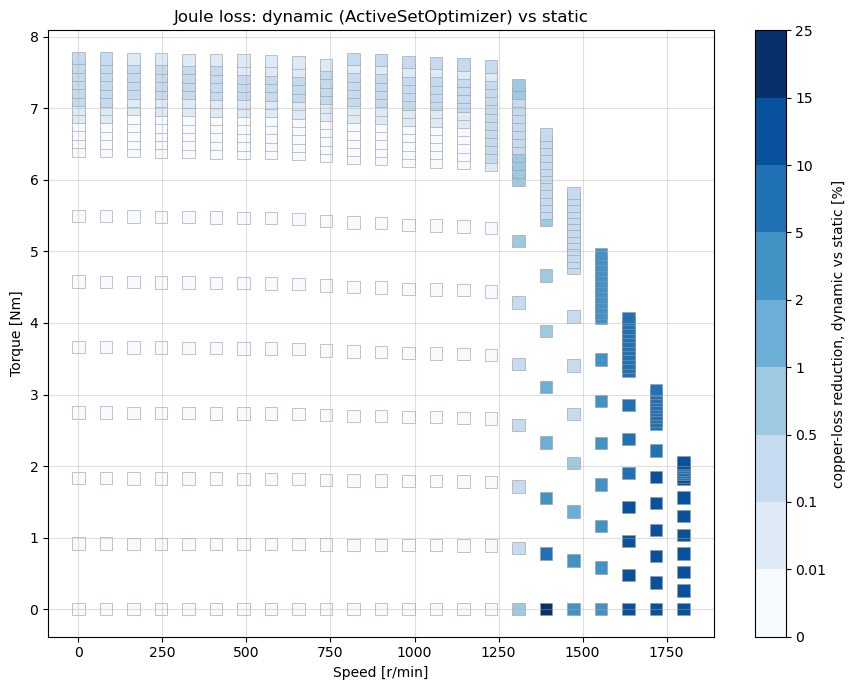

In [8]:
rpm_vec = vec_omega * const_mech_speed
omega_2d = np.broadcast_to(rpm_vec[None, :], (N_TORQ, N_OMEGA))
torq_2d = grid_torq_neural

from matplotlib.colors import BoundaryNorm, SymLogNorm

joule_static = grid_static["grid_joule_loss"]
joule_dyn = grid_dynamic_old["grid_joule_loss"]
with np.errstate(divide="ignore", invalid="ignore"):
    joule_pct = 100.0 * (joule_dyn - joule_static) / joule_static
both = np.isfinite(joule_pct)

pct = joule_pct[both]
size = 80 if max(N_TORQ, N_OMEGA) > 10 else 600
fig, ax = plt.subplots(figsize=(9, 7))
if np.any(both) and np.nanmax(pct) <= 0.01:
    reduction = np.clip(-pct, 0.0, None)
    bounds = [0, 0.01, 0.1, 0.5, 1, 2, 5, 10, 15, max(25, int(np.ceil(reduction.max())))]
    cmap = plt.get_cmap("Blues", len(bounds) - 1)
    sc = ax.scatter(omega_2d[both], torq_2d[both], c=reduction, cmap=cmap,
                    norm=BoundaryNorm(bounds, cmap.N),
                    s=size, marker="s", edgecolors="0.6", linewidths=0.4)
    cbar = fig.colorbar(sc, ax=ax, ticks=bounds, spacing="uniform",
                        label="Joule-loss reduction, dynamic vs static [%]")
    cbar.ax.set_yticklabels([f"{b:g}" for b in bounds])
else:
    vmax = max(float(np.nanmax(np.abs(pct))), 0.1) if np.any(both) else 1.0
    sc = ax.scatter(omega_2d[both], torq_2d[both], c=pct, cmap="RdBu_r",
                    norm=SymLogNorm(linthresh=0.01, linscale=0.5, vmin=-vmax, vmax=vmax, base=10),
                    s=size, marker="s", edgecolors="0.6", linewidths=0.4)
    fig.colorbar(sc, ax=ax, label="Joule-loss proxy: (dynamic $-$ static) / static [%]")
ax.set_xlabel("Speed [r/min]"); ax.set_ylabel("Torque [Nm]")
ax.set_title("Joule loss: dynamic (ActiveSetOptimizer) vs static")
ax.grid(True, alpha=0.4)
plt.tight_layout()
fig.savefig(os.path.join(summary_dir, "joule_loss_dynamic_vs_static.png"), dpi=130)
plt.show()

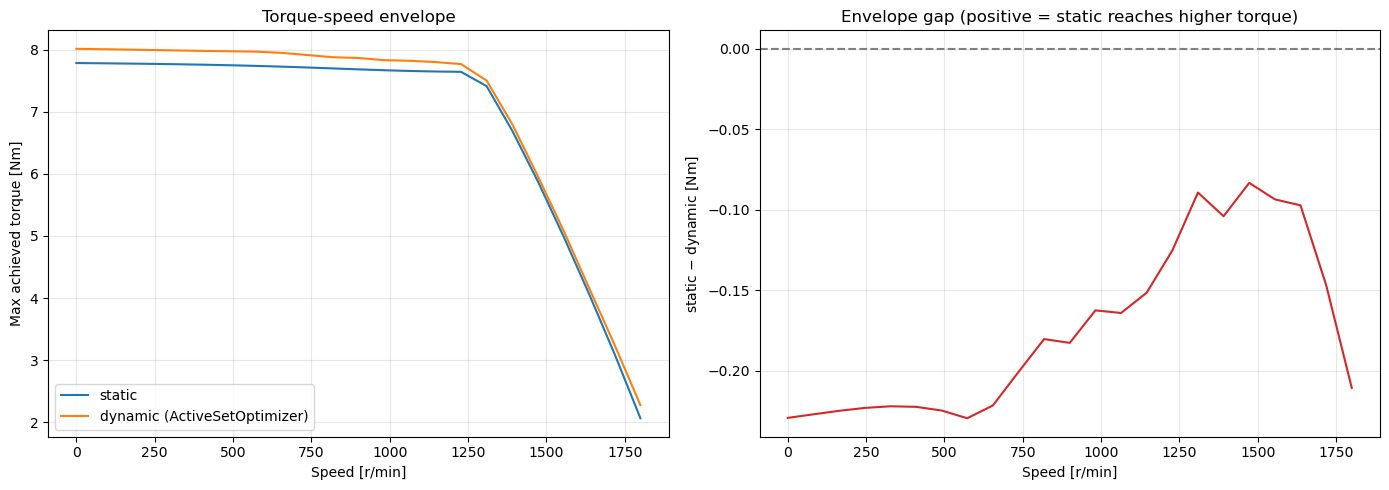

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(rpm_vec, tmax_static_row, label="static", color="tab:blue")
ax1.plot(rpm_vec, tmax_old_row, label="dynamic (ActiveSetOptimizer)", color="tab:orange")
ax1.set_xlabel("Speed [r/min]"); ax1.set_ylabel("Max achieved torque [Nm]")
ax1.set_title("Torque-speed envelope"); ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(rpm_vec, tmax_static_row - tmax_old_row, color="tab:red")
ax2.axhline(0.0, color="gray", ls="--")
ax2.set_xlabel("Speed [r/min]"); ax2.set_ylabel("static $-$ dynamic [Nm]")
ax2.set_title("Envelope gap (positive = static reaches higher torque)")
ax2.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(os.path.join(summary_dir, "envelope_static_vs_dynamic.png"), dpi=130)
plt.show()

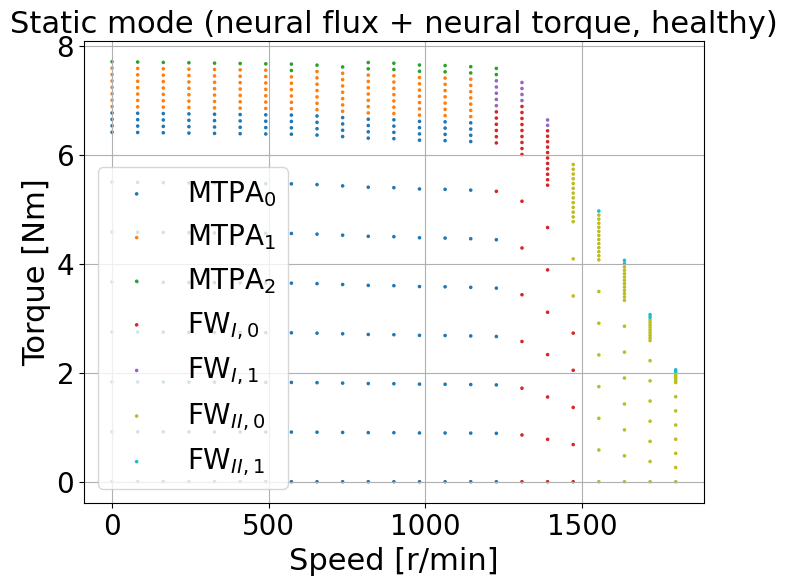

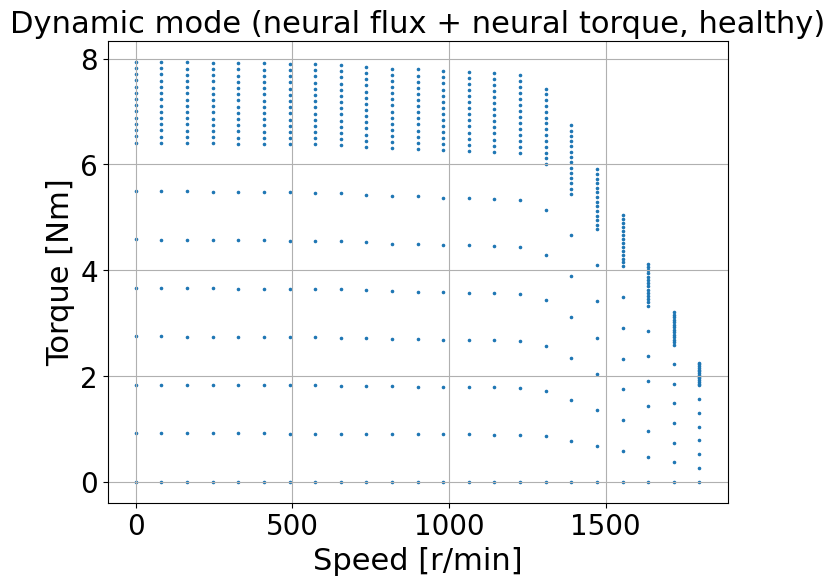

In [10]:
_show = plt.show
plt.show = lambda *a, **k: (plt.gcf().savefig(os.path.join(summary_dir, "region_map_static.png"), dpi=130), _show(*a, **k))
try:
    plot_grid_segments(grid_to_data(grid_static, k_skip=1), title="Static mode (neural flux + neural torque, healthy)", override_torq_2d=torq_2d)
finally:
    plt.show = _show
from current_setpoints.utils.plotting import PlotConfig

solved_dyn = np.isfinite(grid_dynamic_old["grid_joule_loss"])
with plt.rc_context(PlotConfig.get_rc_params()):
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.set_title("Dynamic mode (neural flux + neural torque, healthy)")
    ax.set_xlabel("Speed [r/min]")
    ax.set_ylabel("Torque [Nm]")
    ax.scatter(omega_2d[solved_dyn], torq_2d[solved_dyn], s=10, c="tab:blue", marker=".")
    ax.grid(True)
    fig.savefig(os.path.join(summary_dir, "solved_points_dynamic.png"), dpi=130)
    plt.show()